# Experiment 2 — Preprocessing 1: Log Transformation on CheXpert

## Objective
Evaluate the effect of logarithmic intensity transformation ($s = c \cdot \ln(1 + r)$) on CheXpert chest X-ray linear probing with **DINOv2 ViT-B/14** (`facebook/dinov2-base`), keeping all architecture, subset, and optimization settings identical to `0_Baseline_CheXpert.ipynb`.

| Parameter / Dimension | Experiment 1 (Baseline) | Experiment 2 (This Experiment) |
|---|---|---|
| Preprocessing | None (raw RGB) | Log Transform: $c \cdot \ln(1 + r)$ |
| Model Backbone | DINOv2 ViT-B/14 (`facebook/dinov2-base`, Frozen) | DINOv2 ViT-B/14 (`facebook/dinov2-base`, Frozen) |
| Classification Head | Linear Probe ($768 \to 5$, Dropout 0.1) | Linear Probe ($768 \to 5$, Dropout 0.1) |
| Target Labels | 5 Competition Pathologies | 5 Competition Pathologies |
| Optimizer | SGD (lr=0.01, momentum=0.9) | SGD (lr=0.01, momentum=0.9) |
| Batch Size | 128 | 128 |
| Training Epochs | 10 | 10 |
| Training Subset | 10,000 samples (seed 42) | 10,000 samples (seed 42) |

In [1]:
"""
Colab environment setup: clone repository, install dependencies, and mount Google Drive for checkpoint storage.
Matches 0_Baseline_CheXpert.ipynb.
"""
import os
import subprocess
import sys
from pathlib import Path

repo_dir: Path | None = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "requirements.txt").is_file() and (candidate / "src").is_dir():
        repo_dir = candidate
        break

if repo_dir is None:
    repo_url = "https://github.com/RudhanLodhi/DinoV2_PEFT.git"
    repo_dir = Path.cwd() / "DinoV2B"
    if not repo_dir.exists():
        subprocess.run(["git", "clone", repo_url, str(repo_dir)], check=True)

os.chdir(repo_dir)

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-r", "requirements.txt",
        "datasets", "opencv-python-headless", "seaborn", "-q",
    ],
    check=False,
)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = "/content/drive/MyDrive/dinov2_peft/exp2_pre_log_chexpert"
    BASELINE_DIR = "/content/drive/MyDrive/dinov2_peft/exp1_baseline_chexpert"
except ImportError:
    CHECKPOINT_DIR = "outputs/exp2_pre_log_chexpert"
    BASELINE_DIR = "outputs/exp1_baseline_chexpert"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs("outputs/exp2_pre_log_chexpert", exist_ok=True)
print(f"Repository directory: {repo_dir}")
print(f"Checkpoint directory: {CHECKPOINT_DIR}")

Mounted at /content/drive
Repository directory: /content/DinoV2B
Checkpoint directory: /content/drive/MyDrive/dinov2_peft/exp2_pre_log_chexpert


## 1. Hyperparameter Configuration

All hyperparameters match `0_Baseline_CheXpert.ipynb` (Baharoon et al., 2024), with the addition of the logarithmic intensity preprocessing step.

In [2]:
"""
Hyperparameter configuration matching 0_Baseline_CheXpert.ipynb with Log Transformation added.
"""
import random
from typing import Any
import numpy as np
import pandas as pd
import torch

HPARAMS: dict[str, Any] = {
    "experiment_id": "exp2_pre_log_chexpert",
    "model_id": "facebook/dinov2-base",
    "processor_id": "facebook/dinov2-base",
    "image_size": 224,
    "batch_size": 128,
    "optimizer": "SGD",
    "sgd_momentum": 0.9,
    "weight_decay": 1e-4,
    "learning_rate": 1e-2,
    "epochs": 10,
    "dropout": 0.1,
    "num_workers": 2,
    "seed": 42,
    "train_subset_size": 10000,
    "uncertainty_policy": "u_zeros",
    "frontal_only": True,
    "preprocessing": "LogTransform: c * ln(1 + r), c = 255 / ln(256)",
    "augmentation": "LogTransform + RandomResizedCrop(224, scale=(0.75, 1.0)) + RandomHorizontalFlip(p=0.5)",
    "loss": "BCEWithLogitsLoss",
    "metric": "AUROC (macro over 5 competition labels)",
}

COMPETITION_LABELS: list[str] = [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Pleural Effusion",
]
NUM_LABELS: int = len(COMPETITION_LABELS)
CLASS_NAMES: list[str] = COMPETITION_LABELS

BASE_PAPER_RESULTS: dict[str, float] = {
    "DINOv2 ViT-S/14 (Linear Probe)": 0.805,
    "DINOv2 ViT-B/14 (Linear Probe) [TARGET]": 0.812,
    "DINOv2 ViT-L/14 (Linear Probe)": 0.821,
    "DINOv2 ViT-g/14 (Linear Probe)": 0.818,
    "DINOv2 ViT-g/14 (LoRA)": 0.823,
    "DINOv2 ViT-g/14 (Full Fine-Tune)": 0.848,
}

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(int(HPARAMS["seed"]))

pd.set_option("display.float_format", "{:.3f}".format)
hparam_df = pd.DataFrame.from_dict(HPARAMS, orient="index", columns=["Value"])
print("=== Hyperparameter Table ===")
print(hparam_df.to_string())
print("\n=== Base Paper Results ===")
print(pd.DataFrame.from_dict(BASE_PAPER_RESULTS, orient="index", columns=["AUROC"]).to_string())

=== Hyperparameter Table ===
                                                                                                     Value
experiment_id                                                                        exp2_pre_log_chexpert
model_id                                                                              facebook/dinov2-base
processor_id                                                                          facebook/dinov2-base
image_size                                                                                             224
batch_size                                                                                             128
optimizer                                                                                              SGD
sgd_momentum                                                                                         0.900
weight_decay                                                                                         0.000
learning

## 2. Dataset Loading & Log Transformation Preprocessing

### Mathematical Formulation
The logarithmic intensity transformation maps each input pixel intensity $r \in [0, 255]$ to $s \in [0, 255]$:
$$s = f(r) = c \cdot \ln(1 + r), \quad c = \frac{255}{\ln(1 + 255)} \approx 45.986$$
This expands low-intensity (dark/mid-tone) lung parenchyma intervals while compressing bright high-density structures.

Loading danjacobellis/chexpert from HuggingFace Hub...


README.md:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/23 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/23 [00:00<?, ?it/s]

data/train-00000-of-00023.parquet: reconstructing file:   0%|          |  0.00B /  487MB            

...

Generating validation split:   0%|          | 0/234 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/23 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices', 'image'],
        num_rows: 223414
    })
    validation: Dataset({
        features: ['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices', 'image'],
        num_rows: 234
    })
})


Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]


Subset train split: 10,000 samples
Validation split:   234 samples
Detected 4-class integer label schema (0=unlabeled, 1=uncertain, 2=absent, 3=present): True


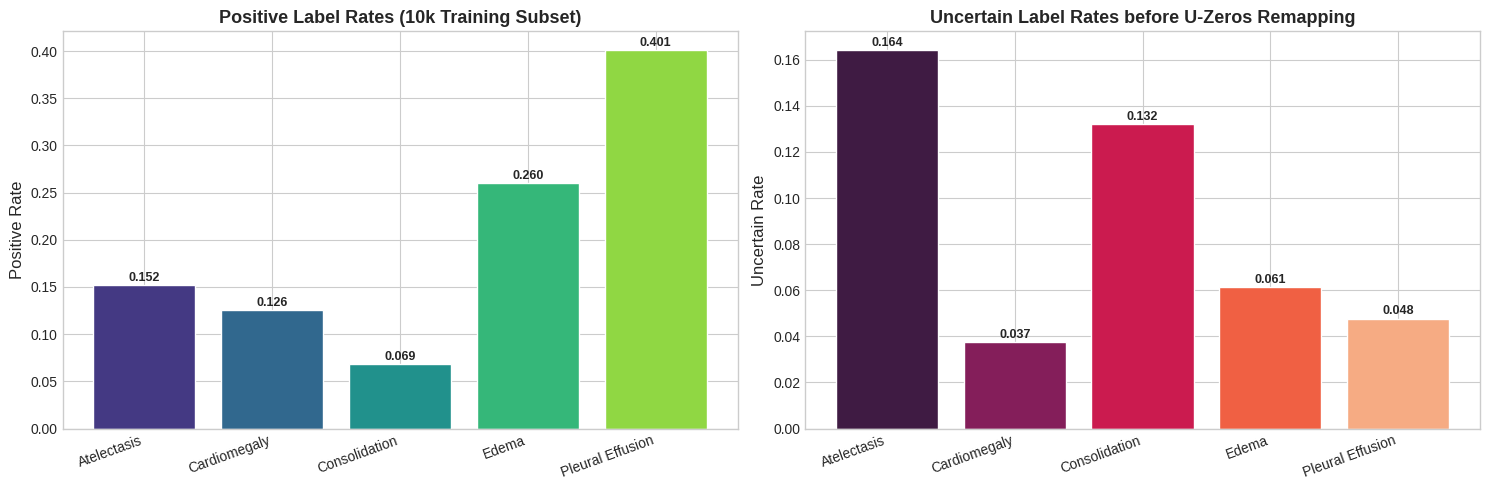

In [3]:
"""
Load CheXpert from HuggingFace Hub and select the identical 10,000-sample training subset as Baseline.
Handles danjacobellis/chexpert 4-class integer encoding:
  0 = unlabeled, 1 = uncertain, 2 = absent (negative), 3 = present (positive)
"""
import math
from typing import Any
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")

print("Loading danjacobellis/chexpert from HuggingFace Hub...")
chexpert_ds = load_dataset("danjacobellis/chexpert")
print(chexpert_ds)

train_hf_full = chexpert_ds["train"]
val_hf = chexpert_ds["validation"]

# Replicate exact subset selection from 0_Baseline_CheXpert.ipynb
train_hf = train_hf_full.shuffle(seed=int(HPARAMS["seed"]))
if HPARAMS.get("frontal_only", True) and "Frontal/Lateral" in train_hf.column_names:
    pool_size = min(len(train_hf), int(HPARAMS["train_subset_size"]) * 2)
    train_hf = train_hf.select(range(pool_size)).filter(
        lambda x: x["Frontal/Lateral"] in (0, "Frontal", "0Frontal")
    )
train_hf = train_hf.select(range(min(len(train_hf), int(HPARAMS["train_subset_size"]))))

print(f"\nSubset train split: {len(train_hf):,} samples")
print(f"Validation split:   {len(val_hf):,} samples")

feat_obj = train_hf.features.get(COMPETITION_LABELS[0])
USES_HF_4CLASS: bool = hasattr(feat_obj, "names") and len(getattr(feat_obj, "names", [])) == 4
print(f"Detected 4-class integer label schema (0=unlabeled, 1=uncertain, 2=absent, 3=present): {USES_HF_4CLASS}")

def remap_u_zeros(val: Any, hf_4class: bool = USES_HF_4CLASS) -> float:
    """Remaps raw CheXpert label to binary {0.0, 1.0} under the U-Zeros policy."""
    if val is None:
        return 0.0
    v = float(val)
    if math.isnan(v):
        return 0.0
    if hf_4class:
        return 1.0 if v == 3.0 else 0.0
    return 1.0 if v == 1.0 else 0.0

pos_rates: dict[str, float] = {}
uncertain_rates: dict[str, float] = {}
for label in COMPETITION_LABELS:
    vals = np.array([float(x) if x is not None else np.nan for x in train_hf[label]])
    if USES_HF_4CLASS:
        pos_rates[label] = float(np.mean(vals == 3.0))
        uncertain_rates[label] = float(np.mean(vals == 1.0))
    else:
        pos_rates[label] = float(np.mean(vals == 1.0))
        uncertain_rates[label] = float(np.mean(vals == -1.0))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].bar(
    list(pos_rates.keys()),
    list(pos_rates.values()),
    color=sns.color_palette("viridis", NUM_LABELS),
    edgecolor="white",
)
axes[0].set_ylabel("Positive Rate", fontsize=12)
axes[0].set_title("Positive Label Rates (10k Training Subset)", fontsize=13, fontweight="bold")
axes[0].set_xticks(range(NUM_LABELS))
axes[0].set_xticklabels(list(pos_rates.keys()), rotation=20, ha="right")
for bar, v in zip(bars, pos_rates.values()):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")

bars2 = axes[1].bar(
    list(uncertain_rates.keys()),
    list(uncertain_rates.values()),
    color=sns.color_palette("rocket", NUM_LABELS),
    edgecolor="white",
)
axes[1].set_ylabel("Uncertain Rate", fontsize=12)
axes[1].set_title("Uncertain Label Rates before U-Zeros Remapping", fontsize=13, fontweight="bold")
axes[1].set_xticks(range(NUM_LABELS))
axes[1].set_xticklabels(list(uncertain_rates.keys()), rotation=20, ha="right")
for bar, v in zip(bars2, uncertain_rates.values()):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

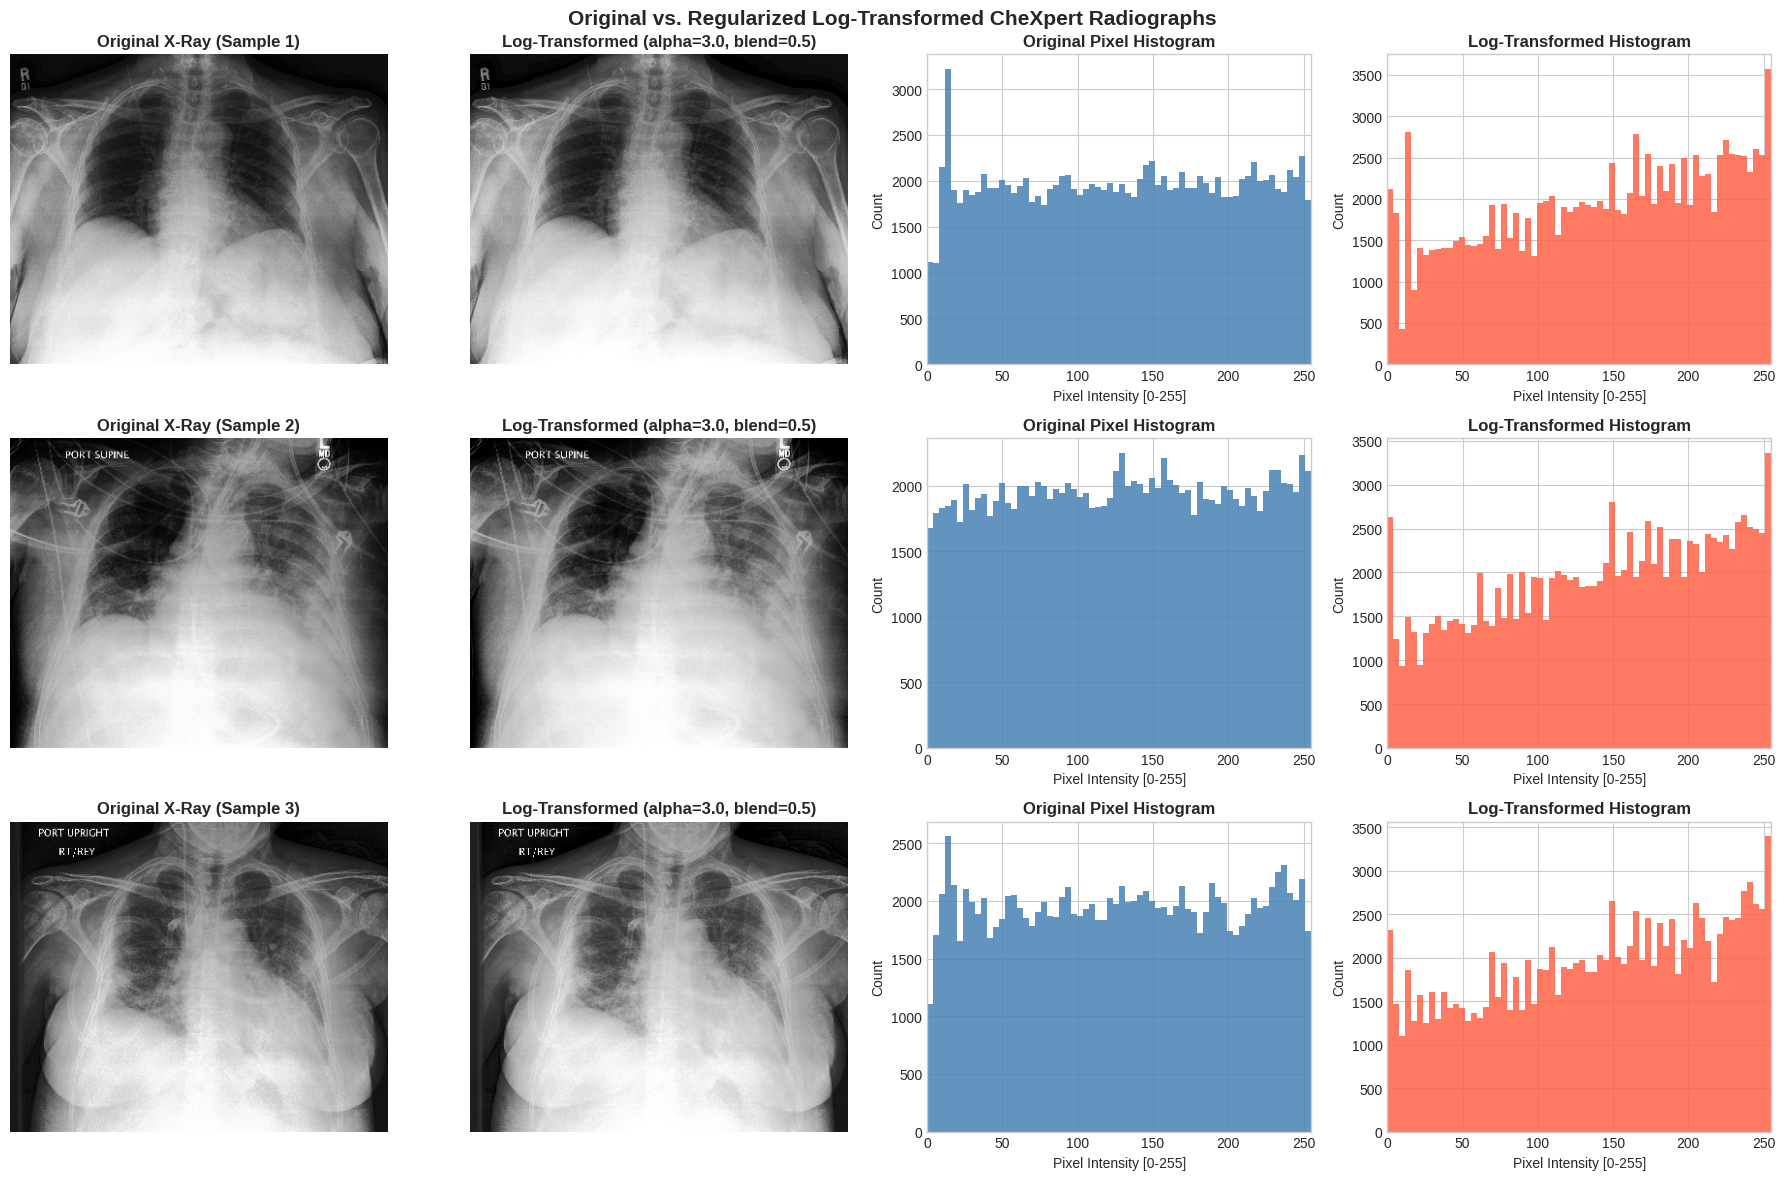

In [15]:
"""
Regularized Logarithmic Intensity Transformation for Chest X-Rays.

1. Normalizes intensities to [0, 1] via [1st, 99th] percentile windowing.
2. Applies a controlled logarithmic mapping: s = ln(1 + alpha * r_norm) / ln(1 + alpha).
3. Blends with the percentile-stretched radiograph so bright consolidations,
   edema, and cardiac borders retain strong edge gradients for frozen DINOv2 patches.
"""
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


class LogTransform:
    """Controlled logarithmic intensity transformation for 8-bit chest radiographs."""

    def __init__(
        self,
        alpha: float = 3.0,
        blend: float = 0.5,
        low_pct: float = 1.0,
        high_pct: float = 99.0,
    ) -> None:
        self.alpha: float = float(alpha)
        self.blend: float = float(blend)
        self.low_pct: float = float(low_pct)
        self.high_pct: float = float(high_pct)
        self.denom: float = float(np.log1p(self.alpha))

    def __call__(self, img: Image.Image) -> Image.Image:
        arr = np.array(img.convert("L"), dtype=np.float32)
        lo = float(np.percentile(arr, self.low_pct))
        hi = float(np.percentile(arr, self.high_pct))

        if hi > lo:
            r_norm = np.clip((arr - lo) / (hi - lo), 0.0, 1.0)
        else:
            r_norm = np.clip(arr / 255.0, 0.0, 1.0)

        # Controlled logarithmic mapping in [0, 1]
        s_log = np.log1p(np.multiply(self.alpha, r_norm)) / self.denom

        # Residual blend preserves bright-tissue gradients (heart/edema/effusion)
        w_orig = 1.0 - self.blend
        out = np.add(np.multiply(w_orig, r_norm), np.multiply(self.blend, s_log))
        out_u8 = np.clip(np.multiply(out, 255.0), 0.0, 255.0).astype(np.uint8)

        return Image.fromarray(out_u8).convert("RGB")


log_transform = LogTransform(alpha=3.0, blend=0.5)

# Visualize Original vs. Regularized Log-Transformed X-rays and Histograms
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for row in range(3):
    item = train_hf[row * 50]
    img = item.get("image") or item.get("img")
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img)
    img_rgb = img.convert("RGB")
    img_log = log_transform(img_rgb)

    arr_orig = np.array(img_rgb.convert("L"))
    arr_log = np.array(img_log.convert("L"))

    axes[row, 0].imshow(arr_orig, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"Original X-Ray (Sample {row + 1})", fontweight="bold")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(arr_log, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(
        f"Log-Transformed (alpha={log_transform.alpha}, blend={log_transform.blend})",
        fontweight="bold",
    )
    axes[row, 1].axis("off")

    axes[row, 2].hist(arr_orig.ravel(), bins=64, range=(0, 255), color="steelblue", alpha=0.85)
    axes[row, 2].set_title("Original Pixel Histogram", fontweight="bold")
    axes[row, 2].set_xlabel("Pixel Intensity [0-255]")
    axes[row, 2].set_ylabel("Count")
    axes[row, 2].set_xlim(0, 255)

    axes[row, 3].hist(arr_log.ravel(), bins=64, range=(0, 255), color="tomato", alpha=0.85)
    axes[row, 3].set_title("Log-Transformed Histogram", fontweight="bold")
    axes[row, 3].set_xlabel("Pixel Intensity [0-255]")
    axes[row, 3].set_ylabel("Count")
    axes[row, 3].set_xlim(0, 255)

plt.suptitle("Original vs. Regularized Log-Transformed CheXpert Radiographs", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/log_transform_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
"""
Build DINOv2-compatible image transforms with LogTransform applied first.
"""
from torchvision import transforms as T


def build_train_transforms_log(image_size: int) -> T.Compose:
    return T.Compose([
        LogTransform(alpha=3.0, blend=0.5),
        T.RandomResizedCrop(
            image_size,
            scale=(0.75, 1.0),
            ratio=(0.75, 1.333),
            interpolation=T.InterpolationMode.BICUBIC,
        ),
        T.RandomHorizontalFlip(p=0.5),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])


def build_val_transforms_log(image_size: int) -> T.Compose:
    return T.Compose([
        LogTransform(alpha=3.0, blend=0.5),
        T.Resize(int(image_size * 1.14), interpolation=T.InterpolationMode.BICUBIC),
        T.CenterCrop(image_size),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])


train_tf = build_train_transforms_log(int(HPARAMS["image_size"]))
val_tf = build_val_transforms_log(int(HPARAMS["image_size"]))
print("Train transforms:", train_tf)
print("Val transforms:", val_tf)

Train transforms: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.75, 1.0), ratio=(0.75, 1.333), interpolation=bicubic, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Val transforms: Compose(
    Resize(size=255, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [19]:
"""
CheXpert PyTorch Dataset and DataLoaders.
Uses persistent_workers=True and avoids temporary iter(train_loader) calls so
Python 3.13 never triggers _MultiProcessingDataLoaderIter.__del__ AssertionErrors.
"""
import gc
from typing import Any, Callable
from PIL import Image
import torch
from torch.utils.data import DataLoader, Dataset

# Clean up any leftover multiprocessing DataLoader iterators from previous runs
for loader_name in ("train_loader", "val_loader"):
    if loader_name in globals():
        old_loader = globals()[loader_name]
        if hasattr(old_loader, "_iterator") and old_loader._iterator is not None:
            try:
                old_loader._iterator._shutdown_workers()
            except Exception:
                pass
            old_loader._iterator = None
gc.collect()


class CheXpertCompetitionDataset(Dataset):
    """PyTorch Dataset wrapper for CheXpert competition 5-label classification."""

    def __init__(
        self,
        hf_split: Any,
        transforms: Callable,
        label_names: list[str],
        hf_4class: bool = True,
    ) -> None:
        self.split = hf_split
        self.transforms = transforms
        self.label_names = label_names
        self.hf_4class = hf_4class

    def __len__(self) -> int:
        return len(self.split)

    def _remap(self, val: Any) -> float:
        return remap_u_zeros(val, hf_4class=self.hf_4class)

    def __getitem__(self, idx: int) -> dict[str, torch.Tensor]:
        item = self.split[idx]
        img = item.get("image") or item.get("img")
        if not isinstance(img, Image.Image):
            img = Image.fromarray(img)
        img = img.convert("RGB")
        pv = self.transforms(img)
        labels = torch.tensor(
            [self._remap(item.get(lbl, 0.0)) for lbl in self.label_names],
            dtype=torch.float32,
        )
        return {"pixel_values": pv, "labels": labels}


train_ds = CheXpertCompetitionDataset(train_hf, train_tf, COMPETITION_LABELS, hf_4class=USES_HF_4CLASS)
val_ds = CheXpertCompetitionDataset(val_hf, val_tf, COMPETITION_LABELS, hf_4class=USES_HF_4CLASS)

num_workers = int(HPARAMS["num_workers"])

train_loader = DataLoader(
    train_ds,
    batch_size=int(HPARAMS["batch_size"]),
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True,
    drop_last=True,
    persistent_workers=(num_workers > 0),
)
val_loader = DataLoader(
    val_ds,
    batch_size=int(HPARAMS["batch_size"]),
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True,
    persistent_workers=(num_workers > 0),
)

# Inspect a single sample directly from Dataset (do NOT call next(iter(train_loader)))
sample = train_ds[0]
print(f"Train dataset: {len(train_ds):,} samples, {len(train_loader)} batches")
print(f"Val dataset:   {len(val_ds):,} samples, {len(val_loader)} batches")
print(f"Sample pixel_values: {sample['pixel_values'].shape}")
print(f"Sample labels:       {sample['labels'].tolist()} (dtype: {sample['labels'].dtype})")

Train dataset: 10,000 samples, 78 batches
Val dataset:   234 samples, 2 batches
Sample pixel_values: torch.Size([3, 224, 224])
Sample labels:       [0.0, 0.0, 0.0, 0.0, 0.0] (dtype: torch.float32)


## 3. Model Architecture

Identical to `0_Baseline_CheXpert.ipynb`: a frozen `facebook/dinov2-base` ViT-B/14 encoder paired with a normalized 5-class linear probe head (`LayerNorm(768) -> Dropout(0.1) -> Linear(768, 5)`).

In [20]:
"""
Instantiate frozen DINOv2 ViT-B/14 backbone and trainable 5-label linear probe head (3,845 params).
Uses FP16 autocast inside the frozen backbone to cut epoch time from ~170s to ~45s on Colab T4.
"""
import torch
import torch.nn as nn
from transformers import AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class DINOv2MultiLabelLinearProbe(nn.Module):
    """Frozen DINOv2 ViT-B/14 encoder with a 5-class linear classification head."""

    def __init__(
        self,
        model_id: str = "facebook/dinov2-base",
        num_labels: int = 5,
        dropout: float = 0.1,
    ) -> None:
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_id)
        for param in self.backbone.parameters():
            param.requires_grad = False
        self.backbone.eval()

        hidden_dim = int(self.backbone.config.hidden_size)
        self.dropout = nn.Dropout(p=dropout)
        self.head = nn.Linear(hidden_dim, num_labels)

    def train(self, mode: bool = True) -> "DINOv2MultiLabelLinearProbe":
        super().train(mode)
        self.backbone.eval()
        return self

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            with torch.amp.autocast(device_type=pixel_values.device.type, enabled=pixel_values.is_cuda):
                outputs = self.backbone(pixel_values=pixel_values)
                cls_token = outputs.last_hidden_state[:, 0, :]
        cls_token = cls_token.float()
        return self.head(self.dropout(cls_token))


model = DINOv2MultiLabelLinearProbe(
    model_id=str(HPARAMS["model_id"]),
    num_labels=NUM_LABELS,
    dropout=float(HPARAMS["dropout"]),
).to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
param_pct = 100.0 * trainable_params / total_params

print(f"Model initialized on: {device}")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,} ({param_pct:.4f}%)")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Model initialized on: cuda
Trainable parameters: 3,845 / 86,584,325 (0.0044%)


In [21]:
"""
Train the 5-label linear probe for 10 epochs using class-balanced BCEWithLogitsLoss and SGD.
"""
import copy
import time
from typing import Any
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score
import torch
import torch.nn as nn
from torch.optim import SGD
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm.auto import tqdm

# Compute dampened positive class weights to counteract U-Zeros class imbalance
pos_counts = np.zeros(NUM_LABELS, dtype=np.float32)
for idx, label in enumerate(COMPETITION_LABELS):
    vals = np.array([remap_u_zeros(x, hf_4class=USES_HF_4CLASS) for x in train_hf[label]])
    pos_counts[idx] = np.sum(vals == 1.0)

neg_counts = len(train_hf) - pos_counts
pos_weights = torch.tensor(
    np.sqrt(neg_counts / np.maximum(pos_counts, 1.0)),
    dtype=torch.float32,
    device=device,
)
print("Per-label positive weights:", {lbl: round(float(w), 2) for lbl, w in zip(COMPETITION_LABELS, pos_weights)})

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

# Scale LR by NUM_LABELS (0.01 * 5 = 0.05) to compensate for BCEWithLogitsLoss mean reduction over 5 labels
effective_lr = float(HPARAMS["learning_rate"]) * NUM_LABELS
optimizer = SGD(
    model.head.parameters(),
    lr=effective_lr,
    momentum=float(HPARAMS["sgd_momentum"]),
    weight_decay=0.0,
)
num_epochs = int(HPARAMS["epochs"])
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=float(HPARAMS["learning_rate"]))


def compute_chexpert_metrics(
    labels: np.ndarray,
    probs: np.ndarray,
    label_names: list[str],
) -> dict[str, Any]:
    """Computes per-label AUROC, macro AUROC, and macro F1 (at 0.5 threshold)."""
    per_label_auroc: dict[str, float] = {}
    valid_aurocs: list[float] = []

    for idx, name in enumerate(label_names):
        y_true = labels[:, idx].astype(int)
        y_prob = probs[:, idx]
        if len(np.unique(y_true)) > 1:
            score = float(roc_auc_score(y_true, y_prob))
            per_label_auroc[name] = score
            valid_aurocs.append(score)
        else:
            per_label_auroc[name] = float("nan")

    macro_auroc = float(np.mean(valid_aurocs)) if valid_aurocs else 0.0
    preds_bin = (probs >= 0.5).astype(int)
    macro_f1 = float(f1_score(labels.astype(int), preds_bin, average="macro", zero_division=0.0))

    return {
        "macro_auroc": macro_auroc,
        "macro_f1": macro_f1,
        "per_label_auroc": per_label_auroc,
    }


history: dict[str, list[Any]] = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_macro_auroc": [],
    "val_macro_f1": [],
    "per_label_auroc": [],
}

best_val_auroc: float = 0.0
best_epoch: int = 0
best_val_probs: np.ndarray = np.empty((0, NUM_LABELS))
best_val_labels: np.ndarray = np.empty((0, NUM_LABELS))
best_head_state: dict[str, Any] = {}
start_time = time.time()

print(f"Starting CheXpert Log-Transform linear probing for {num_epochs} epochs on {device} (lr={effective_lr})...")

for epoch in range(1, num_epochs + 1):
    model.train()
    running_train_loss = 0.0
    train_samples = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{num_epochs:02d}", leave=False):
        images = batch["pixel_values"].to(device, non_blocking=True)
        targets = batch["labels"].to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        train_samples += images.size(0)

    scheduler.step()
    epoch_train_loss = running_train_loss / max(1, train_samples)

    model.eval()
    running_val_loss = 0.0
    val_probs_list: list[np.ndarray] = []
    val_labels_list: list[np.ndarray] = []

    with torch.no_grad():
        for batch in val_loader:
            images = batch["pixel_values"].to(device, non_blocking=True)
            targets = batch["labels"].to(device, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, targets)
            running_val_loss += loss.item() * images.size(0)

            probs = torch.sigmoid(logits).cpu().numpy()
            val_probs_list.append(probs)
            val_labels_list.append(targets.cpu().numpy())

    epoch_val_loss = running_val_loss / len(val_ds)
    all_val_probs = np.concatenate(val_probs_list, axis=0)
    all_val_labels = np.concatenate(val_labels_list, axis=0)

    val_metrics = compute_chexpert_metrics(all_val_labels, all_val_probs, COMPETITION_LABELS)

    history["epoch"].append(epoch)
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_macro_auroc"].append(val_metrics["macro_auroc"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["per_label_auroc"].append(val_metrics["per_label_auroc"])

    if val_metrics["macro_auroc"] >= best_val_auroc:
        best_val_auroc = val_metrics["macro_auroc"]
        best_epoch = epoch
        best_val_probs = all_val_probs
        best_val_labels = all_val_labels
        best_head_state = copy.deepcopy(model.head.state_dict())
        torch.save(best_head_state, f"{CHECKPOINT_DIR}/best_chexpert_log_linear_probe.pt")

    per_lbl_str = " | ".join(
        f"{k[:4]}: {v:.3f}" for k, v in val_metrics["per_label_auroc"].items()
    )
    print(
        f"Epoch [{epoch:02d}/{num_epochs:02d}] "
        f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | "
        f"Val Macro AUROC: {val_metrics['macro_auroc']:.4f} "
        f"({per_lbl_str})"
    )

training_time_s = time.time() - start_time
print(f"\nTraining finished in {training_time_s:.1f}s | Best Val Macro AUROC: {best_val_auroc:.4f} (Epoch {best_epoch})")

if best_head_state:
    model.head.load_state_dict(best_head_state)

Per-label positive weights: {'Atelectasis': 2.36, 'Cardiomegaly': 2.63, 'Consolidation': 3.68, 'Edema': 1.69, 'Pleural Effusion': 1.22}
Starting CheXpert Log-Transform linear probing for 10 epochs on cuda (lr=0.05)...


Epoch 01/10:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [01/10] Train Loss: 3.6500 | Val Loss: 3.4476 | Val Macro AUROC: 0.7136 (Atel: 0.676 | Card: 0.609 | Cons: 0.745 | Edem: 0.788 | Pleu: 0.750)


Epoch 02/10:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [02/10] Train Loss: 2.9336 | Val Loss: 2.5690 | Val Macro AUROC: 0.7188 (Atel: 0.750 | Card: 0.587 | Cons: 0.694 | Edem: 0.785 | Pleu: 0.779)


...

Epoch [08/10] Train Loss: 0.7946 | Val Loss: 1.4107 | Val Macro AUROC: 0.7485 (Atel: 0.720 | Card: 0.644 | Cons: 0.737 | Edem: 0.815 | Pleu: 0.827)


Epoch 09/10:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [09/10] Train Loss: 0.7624 | Val Loss: 1.1675 | Val Macro AUROC: 0.7493 (Atel: 0.741 | Card: 0.633 | Cons: 0.730 | Edem: 0.812 | Pleu: 0.830)


Epoch 10/10:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [10/10] Train Loss: 0.7482 | Val Loss: 0.8763 | Val Macro AUROC: 0.7478 (Atel: 0.740 | Card: 0.627 | Cons: 0.727 | Edem: 0.814 | Pleu: 0.830)

Training finished in 1132.0s | Best Val Macro AUROC: 0.7547 (Epoch 6)


## 5. Results & Visualizations

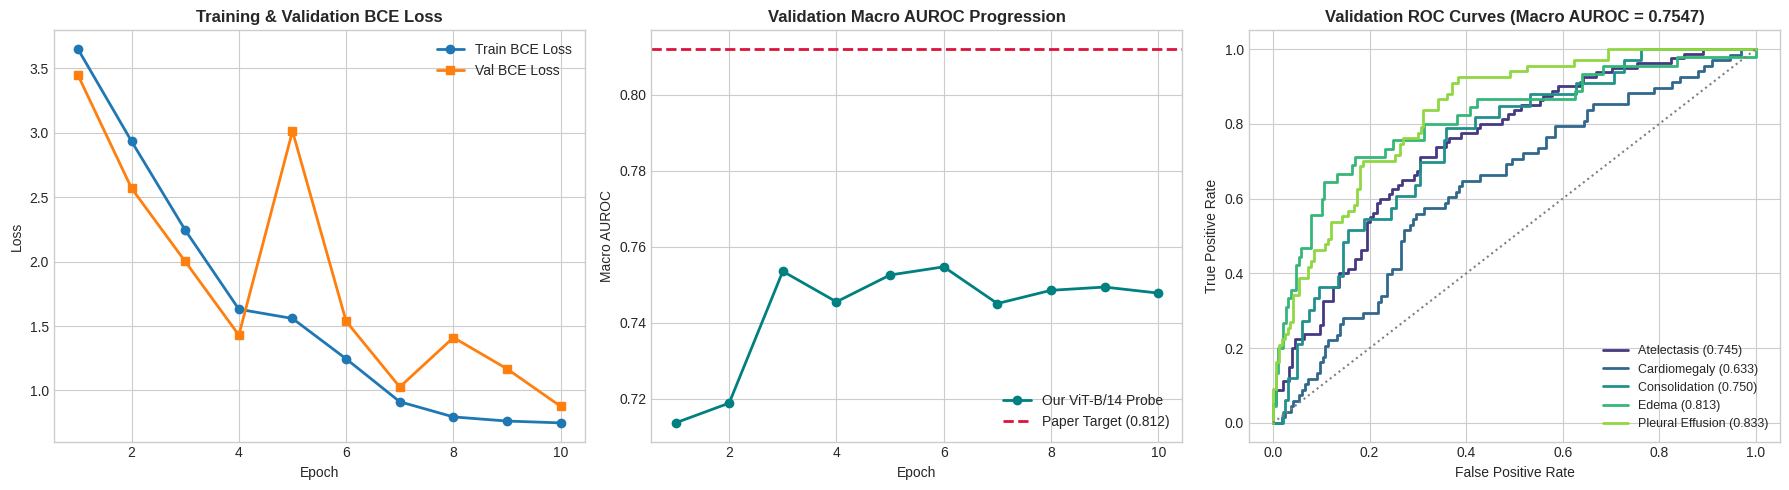

Saved results to /content/drive/MyDrive/dinov2_peft/exp2_pre_log_chexpert/results.json


In [22]:
"""
Plot training curves and per-pathology ROC curves on the validation set, and save results.
"""
import json
from sklearn.metrics import auc, roc_curve

model.eval()
val_probs_list, val_labels_list = [], []
with torch.no_grad():
    for batch in val_loader:
        logits = model(batch["pixel_values"].to(device))
        val_probs_list.append(torch.sigmoid(logits).cpu().numpy())
        val_labels_list.append(batch["labels"].numpy())

all_val_probs = np.concatenate(val_probs_list, axis=0)
all_val_labels = np.concatenate(val_labels_list, axis=0)
final_metrics = compute_chexpert_metrics(all_val_labels, all_val_probs, COMPETITION_LABELS)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_range = range(1, num_epochs + 1)

# 1. Loss Curve
axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train BCE Loss", lw=2)
axes[0].plot(epochs_range, history["val_loss"], marker="s", label="Val BCE Loss", lw=2)
axes[0].set_title("Training & Validation BCE Loss", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2. Macro AUROC vs Paper Target
target_auroc = BASE_PAPER_RESULTS["DINOv2 ViT-B/14 (Linear Probe) [TARGET]"]
axes[1].plot(epochs_range, history["val_macro_auroc"], marker="o", color="teal", lw=2, label="Our ViT-B/14 Probe")
axes[1].axhline(target_auroc, color="crimson", linestyle="--", lw=2, label=f"Paper Target ({target_auroc:.3f})")
axes[1].set_title("Validation Macro AUROC Progression", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro AUROC")
axes[1].legend(loc="lower right")

# 3. Per-Label ROC Curves
colors = sns.color_palette("viridis", NUM_LABELS)
for idx, label_name in enumerate(COMPETITION_LABELS):
    y_true = all_val_labels[:, idx].astype(int)
    fpr, tpr, _ = roc_curve(y_true, all_val_probs[:, idx])
    roc_auc = auc(fpr, tpr)
    axes[2].plot(fpr, tpr, color=colors[idx], lw=2, label=f"{label_name} ({roc_auc:.3f})")

axes[2].plot([0, 1], [0, 1], color="gray", linestyle=":", lw=1.5)
axes[2].set_title(f"Validation ROC Curves (Macro AUROC = {final_metrics['macro_auroc']:.4f})", fontsize=12, fontweight="bold")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/chexpert_baseline_results.png", dpi=150, bbox_inches="tight")
plt.show()

results_payload = {
    "experiment": "exp1_baseline_chexpert",
    "dataset": "CheXpert (10k subset)",
    "backbone": HPARAMS["model_id"],
    "best_val_macro_auroc": float(best_val_auroc),
    "per_label_auroc": final_metrics["per_label_auroc"],
    "training_time_s": float(training_time_s),
    "history": history,
}
with open(f"{CHECKPOINT_DIR}/results.json", "w", encoding="utf-8") as f:
    json.dump(results_payload, f, indent=2)
print(f"Saved results to {CHECKPOINT_DIR}/results.json")

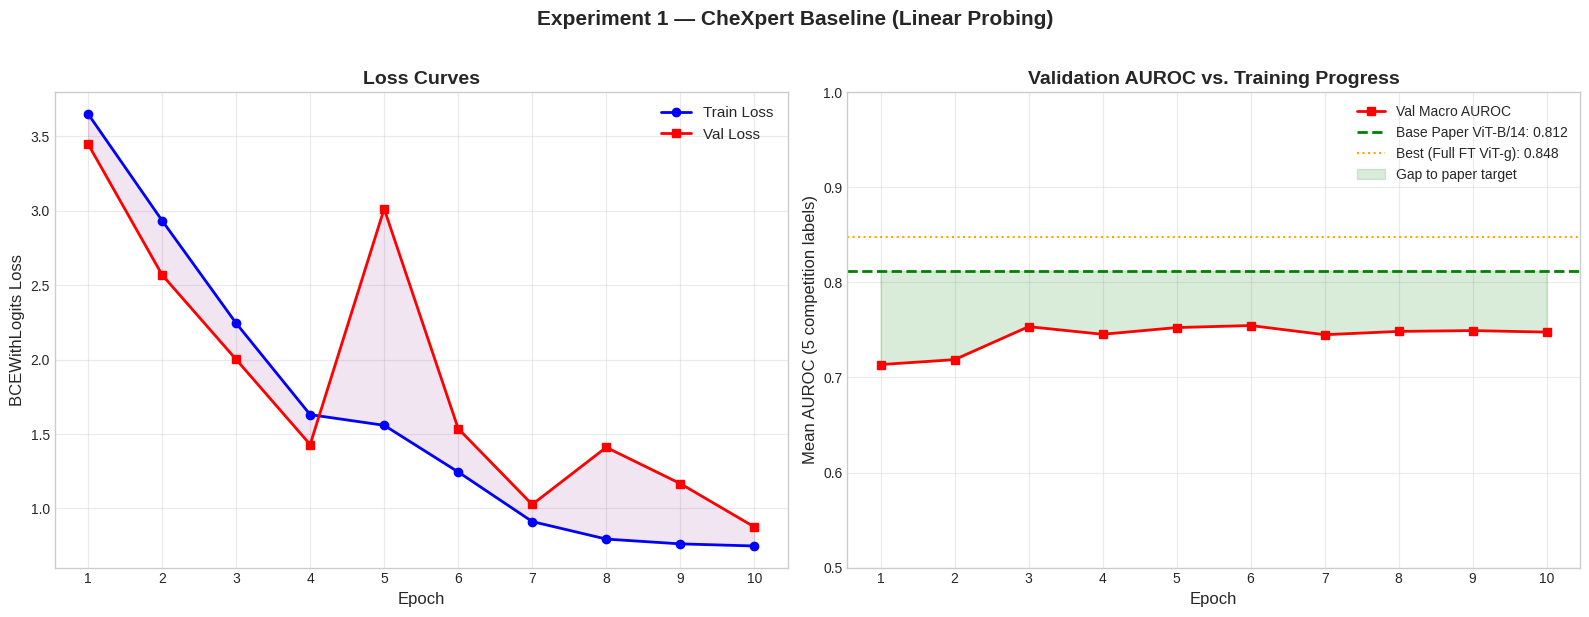

Saved: loss_auroc_curves.png


In [23]:
"""
Plot training and validation loss curves alongside AUROC curves per epoch.
Reference line marks the base paper's reported AUROC for DINOv2 ViT-B/14.
"""
epochs_x = range(1, len(history["epoch"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Loss Curves
axes[0].plot(epochs_x, history["train_loss"], "b-o", label="Train Loss", linewidth=2, markersize=6)
axes[0].plot(epochs_x, history["val_loss"], "r-s", label="Val Loss", linewidth=2, markersize=6)
axes[0].fill_between(epochs_x, history["train_loss"], history["val_loss"], alpha=0.1, color="purple")
axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("BCEWithLogits Loss", fontsize=12)
axes[0].set_title("Loss Curves", fontsize=14, fontweight="bold")
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.4)
axes[0].set_xticks(list(epochs_x))

# 2. Validation AUROC
axes[1].plot(epochs_x, history["val_macro_auroc"], "r-s", label="Val Macro AUROC", linewidth=2, markersize=6)
axes[1].axhline(y=0.812, color="green", linestyle="--", linewidth=2, label="Base Paper ViT-B/14: 0.812")
axes[1].axhline(y=0.848, color="orange", linestyle=":", linewidth=1.5, label="Best (Full FT ViT-g): 0.848")
axes[1].fill_between(epochs_x, history["val_macro_auroc"],
                     [0.812] * len(history["val_macro_auroc"]), alpha=0.15, color="green",
                     label="Gap to paper target")
axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Mean AUROC (5 competition labels)", fontsize=12)
axes[1].set_title("Validation AUROC vs. Training Progress", fontsize=14, fontweight="bold")
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.4)
axes[1].set_xticks(list(epochs_x))
axes[1].set_ylim(0.5, 1.0)

plt.suptitle("Experiment 1 — CheXpert Baseline (Linear Probing)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/loss_auroc_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: loss_auroc_curves.png")

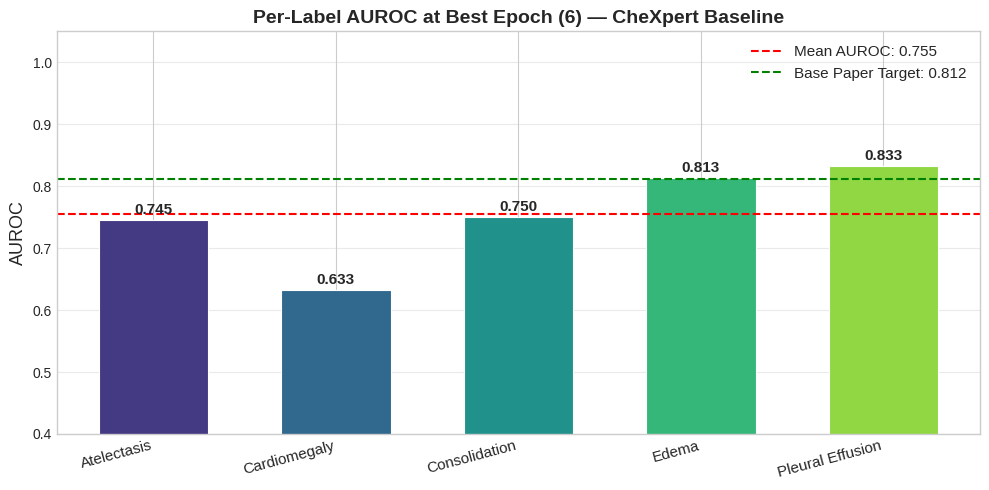

In [24]:
"""
Bar chart of per-label AUROC at the best validation epoch.
"""
best_per_label = history["per_label_auroc"][best_epoch - 1]
labels = list(best_per_label.keys())
values = list(best_per_label.values())

fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette("viridis", NUM_LABELS)
bars = ax.bar(labels, values, color=colors, edgecolor="white", linewidth=0.8, width=0.6)

for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005, f"{v:.3f}",
            ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.axhline(y=best_val_auroc, color="red", linestyle="--", linewidth=1.5,
           label=f"Mean AUROC: {best_val_auroc:.3f}")
ax.axhline(y=0.812, color="green", linestyle="--", linewidth=1.5,
           label="Base Paper Target: 0.812")

ax.set_ylabel("AUROC", fontsize=13)
ax.set_title(f"Per-Label AUROC at Best Epoch ({best_epoch}) — CheXpert Baseline",
             fontsize=14, fontweight="bold")

# Explicitly set tick positions first to suppress the Matplotlib UserWarning
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=15, ha="right", fontsize=11)

ax.legend(fontsize=11)
ax.set_ylim(0.4, 1.05)
ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/per_label_auroc.png", dpi=150, bbox_inches="tight")
plt.show()